In [ ]:
pip install ucimlrepo

In [ ]:
pip install optuna scikeras

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.6/383.6 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.9/231.9 kB 7.5 MB/s eta 0:00:00


In [ ]:
!pip install ydata-profiling optuna-integration

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.1/400.1 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.5/296.5 kB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 687.8/687.8 kB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 40.6 MB/s eta 0:00:00
  Created wheel for htmlmin: filename=htmlmin-0.1.12-py3-none-any.whl size=27081 sha256=ee1e7e08d7c25c3ba756b273c1012a4e322144f682a471be70a41e22de805e99
  Stored in directory: /root/.cache/pip/wheels/8d/55/1a/19cd535375ed1ede0c996405ebffe34b196d78e2d9545723a2
Successfully built htmlmin


## Mount GDrive




In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Imports

In [ ]:
import os
import joblib
from joblib import parallel_backend

import matplotlib
import matplotlib.pyplot as plt

import seaborn as sns

import sklearn
import xgboost

import numpy as np
import pandas as pd
import random

from ydata_profiling import ProfileReport

In [ ]:
from sklearn import set_config
# Set sklearn to show diagrams for pipelines
set_config(display='diagram')

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, fbeta_score, make_scorer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RandomizedSearchCV, ParameterSampler, cross_val_score
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.datasets import make_classification
from sklearn.base import clone
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.metrics import precision_score, recall_score, confusion_matrix, f1_score

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, GlobalMaxPooling1D
from keras.callbacks import EarlyStopping

In [ ]:
from xgboost import XGBClassifier
import xgboost as xgb

In [ ]:
from ucimlrepo import fetch_ucirepo

In [ ]:
from scipy.signal import butter, filtfilt
from scipy.stats import uniform, randint

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.under_sampling import ClusterCentroids

In [ ]:
import optuna
from optuna.storages.journal import JournalStorage, JournalFileBackend

## Import for UCIDATASET

In [ ]:
# fetch dataset
accelerometer_gyro_mobile_phone = fetch_ucirepo(id=755)

# data (as pandas dataframes)
X = accelerometer_gyro_mobile_phone.data.features
y = accelerometer_gyro_mobile_phone.data.targets

# metadata
print(accelerometer_gyro_mobile_phone.metadata)

# variable information
print(accelerometer_gyro_mobile_phone.variables)


{'uci_id': 755, 'name': 'Accelerometer Gyro Mobile Phone', 'repository_url': 'https://archive.ics.uci.edu/dataset/755/accelerometer+gyro+mobile+phone+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/755/data.csv', 'abstract': 'data collected on 2022, in King Saud University in riyadh for recognizing human activities using mobile phone IMU sensors (Accelerometer, and Gyroscope). these activity is calssified to standing(stop), or walking.', 'area': 'Computer Science', 'tasks': ['Classification'], 'characteristics': ['Tabular', 'Sequential', 'Multivariate', 'Time-Series'], 'num_instances': 31991, 'num_features': 8, 'feature_types': ['Real', 'Categorical'], 'demographics': [], 'target_col': None, 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2022, 'last_updated': 'Tue Apr 09 2024', 'dataset_doi': 'https://doi.org/10.3390/s22176513', 'creators': ['Abdullah AlSahly'], 'intro_paper': {'ID': 155, 'type': 'NATIVE', 'tit

## Analizzo brevemente con pandas

In [ ]:
# https://archive.ics.uci.edu/static/public/755/data.csv
mobile_acc_gyro_data = pd.read_csv('https://raw.githubusercontent.com/FornOmega/Human-activity-recognition-using-mobile-phone-IMU-sensors/main/dataset/accelerometer_gyro_mobile_phone_dataset.csv', sep=",")

In [ ]:
mobile_acc_gyro_data
# 6 feature numeriche - continue
# 1 feature categorica --> timestamp

,accX,accY,accZ,gyroX,gyroY,gyroZ,timestamp,Activity
0,-0.496517,3.785628,8.954828,-0.142849,-0.126159,-0.022539,34:22.9,1
1,-0.462388,3.869603,9.281898,0.084349,0.096695,0.092130,34:23.0,1
2,-0.296084,3.820505,8.930728,0.061763,0.051543,0.071287,34:23.1,1
3,-0.469723,3.890110,8.744067,0.007641,0.028679,0.109433,34:23.2,1
4,-0.472418,4.109105,8.941207,-0.123640,0.099057,0.051943,34:23.3,1
...,...,...,...,...,...,...,...,...
31986,-0.488734,1.610800,10.610386,0.079187,-0.174218,-0.050365,03:15.1,1
31987,-0.049397,2.769092,7.008276,-0.083853,0.007656,-0.045658,03:15.2,1
31988,0.291294,3.002007,6.732400,0.005984,-0.058994,-0.087044,03:15.3,1
31989,0.256267,4.069138,8.687933,0.061487,-0.016278,-0.088728,03:15.4,1


In [ ]:
mobile_acc_gyro_data.dtypes

,0
accX,float64
accY,float64
accZ,float64
gyroX,float64
gyroY,float64
gyroZ,float64
timestamp,object
Activity,int64


In [ ]:
mobile_acc_gyro_data.nunique()

,0
accX,15343
accY,18753
accZ,23353
gyroX,31097
gyroY,31048
gyroZ,31063
timestamp,21776
Activity,2


In [ ]:
mobile_acc_gyro_data.describe()

#31991 come descritto 31991 nella "repository"

,accX,accY,accZ,gyroX,gyroY,gyroZ,Activity
count,31991.000000,31991.000000,31991.000000,31991.000000,31991.000000,31991.000000,31991.000000
mean,0.023825,2.153858,9.537909,-0.004493,-0.014756,-0.007021,0.982151
std,0.741396,1.085466,2.056358,0.307643,0.249201,0.266120,0.132404
min,-3.673361,-4.386029,4.296066,-1.470421,-1.430659,-1.894102,0.000000
25%,-0.472193,1.413062,7.794217,-0.149783,-0.162656,-0.154126,1.000000
50%,-0.024998,2.119143,9.406739,0.022301,-0.011060,0.005261,1.000000
75%,0.477208,2.928435,11.158845,0.177978,0.124966,0.152061,1.000000
max,4.678671,6.377039,17.591568,1.332722,1.480135,1.482268,1.000000


In [ ]:
mobile_acc_gyro_data.count()

,0
accX,31991
accY,31991
accZ,31991
gyroX,31991
gyroY,31991
gyroZ,31991
timestamp,31991
Activity,31991


In [ ]:
mobile_acc_gyro_data_activity1=mobile_acc_gyro_data['Activity']
# check
print(mobile_acc_gyro_data_activity1)

0        1
1        1
2        1
3        1
4        1
        ..
31986    1
31987    1
31988    1
31989    1
31990    1
Name: Activity, Length: 31991, dtype: int64


In [ ]:
mobile_acc_gyro_data.head()

,accX,accY,accZ,gyroX,gyroY,gyroZ,timestamp,Activity
0,-0.496517,3.785628,8.954828,-0.142849,-0.126159,-0.022539,34:22.9,1
1,-0.462388,3.869603,9.281898,0.084349,0.096695,0.092130,34:23.0,1
2,-0.296084,3.820505,8.930728,0.061763,0.051543,0.071287,34:23.1,1
3,-0.469723,3.890110,8.744067,0.007641,0.028679,0.109433,34:23.2,1
4,-0.472418,4.109105,8.941207,-0.123640,0.099057,0.051943,34:23.3,1


In [ ]:
mobile_acc_gyro_data.tail()

,accX,accY,accZ,gyroX,gyroY,gyroZ,timestamp,Activity
31986,-0.488734,1.610800,10.610386,0.079187,-0.174218,-0.050365,03:15.1,1
31987,-0.049397,2.769092,7.008276,-0.083853,0.007656,-0.045658,03:15.2,1
31988,0.291294,3.002007,6.732400,0.005984,-0.058994,-0.087044,03:15.3,1
31989,0.256267,4.069138,8.687933,0.061487,-0.016278,-0.088728,03:15.4,1
31990,0.646356,5.273683,10.216704,-0.142294,-0.000884,0.048970,03:15.5,1


In [ ]:
mobile_acc_gyro_data.loc[3000:3500]

,accX,accY,accZ,gyroX,gyroY,gyroZ,timestamp,Activity
3000,-0.617466,1.946702,7.529193,-0.022493,-0.034176,0.356435,57:45.7,1
3001,-0.387394,3.026706,6.065237,0.067276,-0.010266,0.332784,57:45.8,1
3002,-0.451162,3.863616,8.955726,0.022102,-0.316728,0.091901,57:45.9,1
3003,-0.394280,3.390599,11.399245,-0.168825,0.114916,-0.251832,57:46.0,1
3004,0.386047,1.409918,12.170891,-0.766871,0.179139,-0.620699,57:46.1,1
...,...,...,...,...,...,...,...,...
3496,-0.284558,1.476380,11.978391,0.043297,-0.095914,0.320829,00:46.5,1
3497,0.940195,1.856739,9.507778,0.123528,-0.110964,-0.034103,00:46.6,1
3498,-0.052092,2.962939,6.795868,-0.179473,0.256307,-0.669218,00:46.7,1
3499,-0.086071,3.392545,7.985294,0.036440,0.019684,-0.459049,00:46.8,1


In [ ]:
len(mobile_acc_gyro_data[mobile_acc_gyro_data['Activity']==0])

571

In [ ]:
mobile_acc_gyro_data.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
31986,False
31987,False
31988,False
31989,False


In [ ]:
# count of duplicated row on entire dataaset
len(mobile_acc_gyro_data)-len(mobile_acc_gyro_data.drop_duplicates())

144

In [ ]:
# Missing values conteggio
mobile_acc_gyro_data.isnull().sum().sum()

np.int64(0)

# Data Analysis and Preprocessing

In [ ]:
# Creo il dataset rimuovendo la feature timestamp

notime_mobile_acc_gyro_data = mobile_acc_gyro_data.drop(columns="timestamp")

### Dataset Profiling (Pandas Profiling)

Effettuo già la suddivisione del dataset.

In [ ]:
# Prima divisione: training (67%) e temporaneo (33%)
train_set_profiling, temp_set = train_test_split(notime_mobile_acc_gyro_data, test_size=0.33, random_state=42)

In [ ]:
# Profile the train data using the ydata_profiling library
profile=ProfileReport(train_set_profiling, title='Human Activity Recognition Data Report', explorative=True)

In [ ]:
# Save the profile report to an HTML file
profile.to_file("profile_report_HAR.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 7/7 [00:00<00:00,  8.64it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
profile.to_notebook_iframe()

## Data Visualization

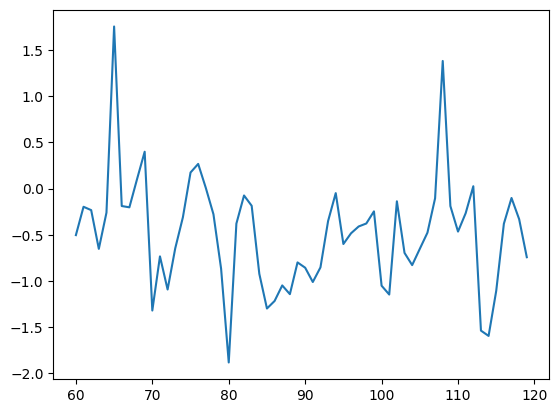

In [ ]:
plt.plot(notime_mobile_acc_gyro_data["accX"][60:120])

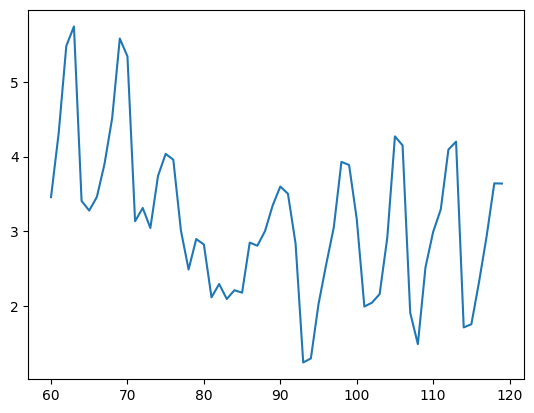

In [ ]:
plt.plot(notime_mobile_acc_gyro_data["accY"][60:120])

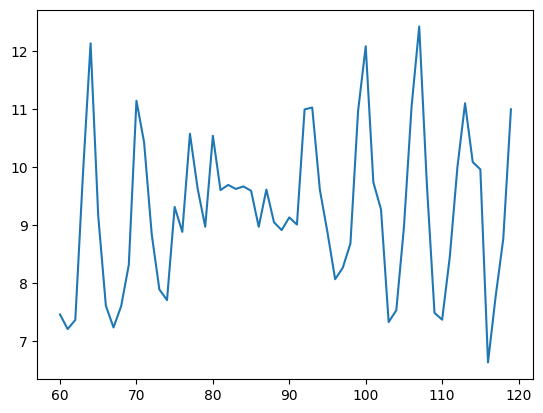

In [ ]:
plt.plot(notime_mobile_acc_gyro_data["accZ"][60:120])

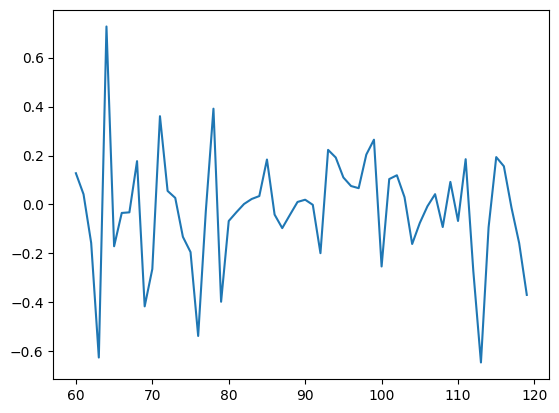

In [ ]:
plt.plot(notime_mobile_acc_gyro_data["gyroX"][60:120])

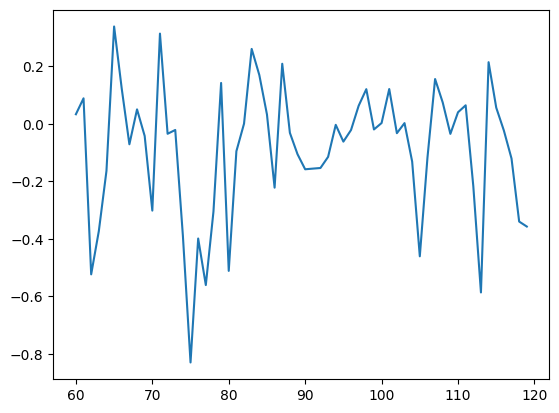

In [ ]:
plt.plot(notime_mobile_acc_gyro_data["gyroY"][60:120])

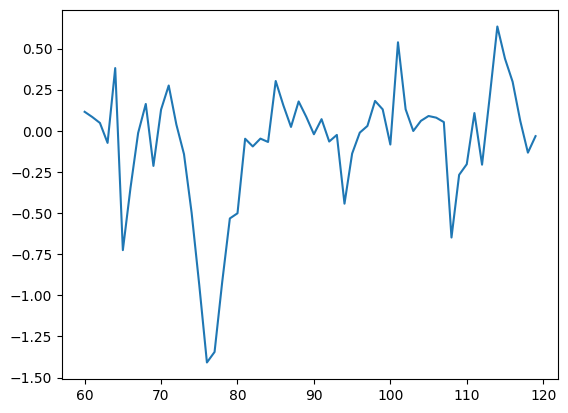

In [ ]:
plt.plot(notime_mobile_acc_gyro_data["gyroZ"][60:120])

In [ ]:
def plot_pie_values_col(ds: pd.DataFrame, column: str, title: str):
    """
    Plotta una pie chart basata sui valori di una colonna specifica di un DataFrame.
    """
    value_counts = ds[column].value_counts()
    filtered_values = value_counts[value_counts > 3]

    # Plotta la pie chart
    filtered_values.plot.pie(figsize=(8, 6), autopct="%1.1f%%")

    # Aggiungi il titolo
    plt.title(title, fontsize=14)
    plt.ylabel('')  # Rimuove l'etichetta assegnata automaticamente
    plt.show()

In [ ]:
mobile_acc_gyro_data[mobile_acc_gyro_data['Activity']==0]

,accX,accY,accZ,gyroX,gyroY,gyroZ,timestamp,Activity
20923,-0.396525,0.550405,9.576037,0.009053,-0.042808,0.023791,05:47.5,0
20924,-0.460742,0.555046,10.204579,-0.030913,-0.014605,0.048749,05:47.6,0
20925,-0.238005,0.727936,9.533675,0.049909,-0.014274,-0.001371,05:47.7,0
20926,-0.413889,0.798290,9.709409,0.020137,0.019136,0.021809,05:47.8,0
20927,-0.445174,0.812959,9.782757,0.016075,-0.002261,0.023203,05:47.9,0
...,...,...,...,...,...,...,...,...
21947,-0.619113,1.714086,9.753567,-0.120803,0.161252,-0.851049,07:30.1,0
21948,-0.706980,1.952240,9.356144,-0.128203,0.090803,-0.324165,07:30.2,0
21949,-0.066162,2.509531,9.760603,0.294427,-0.115590,0.114325,07:30.3,0
21950,-1.192271,0.716560,11.704460,-0.075514,0.608212,0.101588,07:30.4,0


In [ ]:
out_of_bounds = mobile_acc_gyro_data[
    (mobile_acc_gyro_data['accX'] < -1.5) | (mobile_acc_gyro_data['accX'] > 1.5) |
    (mobile_acc_gyro_data['accY'] < 0.0) | (mobile_acc_gyro_data['accY'] > 4.0) |
    (mobile_acc_gyro_data['accZ'] < 6) | (mobile_acc_gyro_data['accZ'] > 14)
]

if not out_of_bounds.empty:
    print("Valori fuori dai limiti trovati:")
    print(out_of_bounds)
else:
    print("Tutti i valori sono entro i limiti specificati.")

Valori fuori dai limiti trovati:
           accX      accY       accZ     gyroX     gyroY     gyroZ timestamp  \
4     -0.472418  4.109105   8.941207 -0.123640  0.099057  0.051943   34:23.3   
5     -0.837359  4.051176   8.473878  0.031954 -0.039420  0.144715   34:23.4   
6     -1.093476  4.698280   8.900940 -0.291323  0.145343 -0.033145   34:23.5   
7     -1.131347  4.305197   8.348439 -0.136222  0.024592  0.256020   34:23.6   
8     -0.628693  4.660259   8.403974 -0.106731  0.015743  0.084673   34:23.7   
...         ...       ...        ...       ...       ...       ...       ...   
31945  0.401465  4.676276  11.567645 -0.357443  0.007471  0.148729   03:11.0   
31962 -0.592468  4.565207  10.443333 -0.347297  0.061152  0.054253   03:12.7   
31979  0.772843  4.875811  11.227253  0.074101 -0.026628 -0.140610   03:14.4   
31989  0.256267  4.069138   8.687933  0.061487 -0.016278 -0.088728   03:15.4   
31990  0.646356  5.273683  10.216704 -0.142294 -0.000884  0.048970   03:15.5   

      

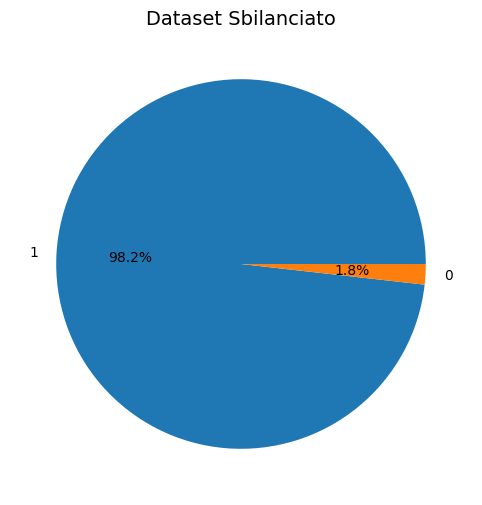

In [ ]:
# Visualizzazione del dataset sbilanciato

plot_pie_values_col(ds=notime_mobile_acc_gyro_data, column="Activity", title="Dataset Sbilanciato")

In [ ]:
print("Lunghezza dataset non bilanciato: " + str(len(notime_mobile_acc_gyro_data)) + " elementi.")

Lunghezza dataset non bilanciato: 31991 elementi.


## HEATMAP


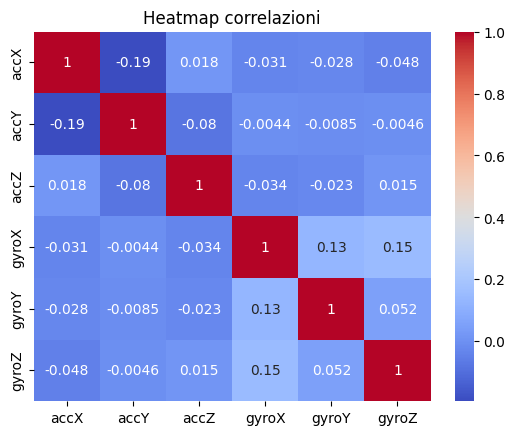

In [ ]:
correlation_mat = notime_mobile_acc_gyro_data[['accX','accY','accZ','gyroX','gyroY','gyroZ']].corr()

sns.heatmap(correlation_mat, annot = True, cmap="coolwarm")
plt.title('Heatmap correlazioni')
plt.show()

# DATA CLEANING:

## Filtraggio dati - paper

SMOOTHING DEI DATI con Butterworth highpass e lowpass filter


The Mahony complementary filter (MCF) can be used to correct gyro data,
and a low-pass filter (LPF) and high-pass filter (HPF) can be used to overcome accelerometer
(acce) and gyroscope (gyro) data spikes, respectively. The Mahony complementary filter
(MCF) can be used to compute the heading angle, as it utilizes gyroscope data to calculate
the carrier attitude, and does not result in error accumulation. Use acce and magnetometer
(mag) data, the MCF corrects the gyro error (as shown in Equations (5) and (6)), and all
sensor data are considered to lie in 3-dimensional space:

### Split

In [ ]:
from sklearn.model_selection import train_test_split

# Suddivisione stratificata: training (67%) e temporaneo (33%)
train_set, temp_set = train_test_split(notime_mobile_acc_gyro_data, test_size=0.33, random_state=42, stratify=notime_mobile_acc_gyro_data['Activity'])

# Suddivisione stratificata del set temporaneo in testing (16.5%) e validazione (16.5%)
test_set, val_set = train_test_split(temp_set, test_size=0.5, random_state=42, stratify=temp_set['Activity'])


## RIMOZIONE DEGLI OUTLIERS

In [ ]:
# Funzione per rilevare gli outlier usando il metodo IQR
def detect_outliers_iqr(df, columns):
    outlier_indices = []

    for column in columns:
        Q1 = df[column].quantile(0.25)
        Q3 = df[column].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Trova gli outlier
        outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

        # Salva gli indici degli outlier
        outlier_indices.extend(outliers.index)

    # Rimuovi gli outlier
    outlier_indices = list(set(outlier_indices))
    return df.drop(index=outlier_indices), outlier_indices

In [ ]:
# Applica la funzione agli outlier sul train_set
no_outliers_trainset, outlier_indices = detect_outliers_iqr(train_set, columns=['accX', 'accY', 'accZ', 'gyroX', 'gyroY', 'gyroZ'])

# Visualizza gli outlier trovati
outliers = train_set.loc[outlier_indices]
print("Outliers detected and removed:")
print(outliers)

# Dopo aver rimosso gli outlier, rimuoviamo la colonna 'outlier' se presente
cleaned_no_outliers_trainset = no_outliers_trainset.drop(columns="outlier", errors='ignore')

Outliers detected and removed:
           accX      accY       accZ     gyroX     gyroY     gyroZ  Activity
8192  -0.155976  3.692970  11.040890 -0.983277 -0.416078 -0.380430         1
8193   0.668210  3.042872  11.682157  0.730522 -0.392117  0.266965         1
16392  2.380200  0.518971  12.453802  0.206137 -0.257428  0.139995         1
24584 -0.284259  2.242786   9.379346  1.332722  0.263365 -0.103747         1
8206   1.881438  1.811084  10.031090  0.370163  0.180689 -0.202553         1
...         ...       ...        ...       ...       ...       ...       ...
16360  2.008523  0.338895  11.583362  0.146107 -0.200370  0.036112         1
24551  0.606688  1.892664   9.332792 -0.844315 -0.317646  0.367588         1
8176   0.397124  2.396965  14.173277 -0.791880 -0.132898 -0.075967         1
16375  2.143093  0.008233  13.597274 -0.423793 -0.231083  0.065109         1
8187  -1.655108  4.119434  10.740914  0.811889  0.408826  0.413927         1

[2527 rows x 7 columns]


In [ ]:
# rimozione outliers

def detect_outliers_std(data, columns, threshold=3):
    """
    Identifica gli outlier in più colonne basandosi sulla deviazione standard.

    Parametri:
    - data: pd.DataFrame -> Il dataset.
    - columns: list -> Lista delle colonne da analizzare.
    - threshold: int -> Numero di deviazioni standard per considerare un valore un outlier.

    Restituisce:
    - Un DataFrame con una colonna aggiuntiva 'outlier' che indica True per gli outlier.
    """
    outlier_flags = pd.DataFrame(index=data.index)

    for column in columns:
        mean = data[column].mean()
        std = data[column].std()
        lower_bound = mean - threshold * std
        upper_bound = mean + threshold * std

        # Flagga gli outlier per questa colonna
        outlier_flags[column] = (data[column] < lower_bound) | (data[column] > upper_bound)

    # Combina i flag
    data['outlier'] = outlier_flags.any(axis=1)
    return data

outlier_data = detect_outliers_std(train_set, columns=['accX', 'accY', 'accZ', 'gyroX', 'gyroY', 'gyroZ'])
outliers = outlier_data[outlier_data['outlier']]

outlier_indices = outliers.index

no_outliers_trainset = train_set.drop(outlier_indices)
cleaned_no_outliers_trainset=no_outliers_trainset.drop(columns="outlier")
print("Lunghezza del trainset dopo aver rimosso gli outliers: " + str(len(cleaned_no_outliers_trainset)) + " elementi.")

Lunghezza del trainset dopo aver rimosso gli outliers: 20646 elementi.


In [ ]:
cleaned_no_outliers_trainset

,accX,accY,accZ,gyroX,gyroY,gyroZ,Activity
2434,-0.114961,1.600921,11.225307,-0.062174,-0.202773,-0.221892,1
12419,1.052162,2.206112,9.068143,-0.103214,0.441333,0.397149,1
4840,-0.671803,2.525997,9.074280,0.583035,0.318318,0.400862,1
18205,-0.455652,2.777325,7.765701,0.298210,-0.101131,0.157332,1
8187,-1.655108,4.119434,10.740914,0.811889,0.408826,0.413927,1
...,...,...,...,...,...,...,...
12813,0.283061,1.256038,7.824828,0.216972,-0.023779,0.066439,1
13028,0.551304,0.912802,8.500074,-0.467953,0.034812,-0.024521,1
18337,0.936004,3.589985,10.974578,0.171272,-0.067477,-0.003393,1
26136,-0.540825,2.092948,7.832462,-0.116298,0.052210,0.168525,1


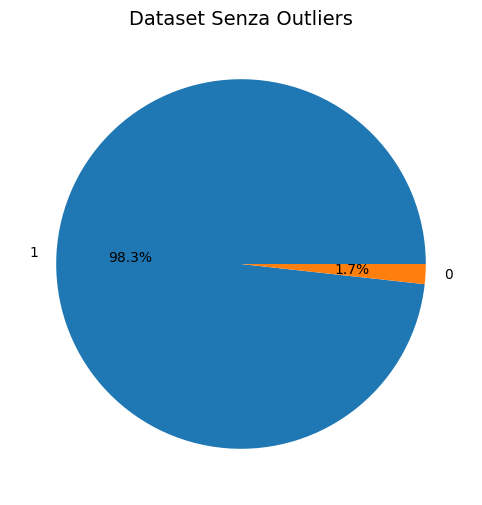

In [ ]:
plot_pie_values_col(ds=cleaned_no_outliers_trainset, column="Activity", title="Dataset Senza Outliers")

#### Data visualization post pre-processing - Histograms

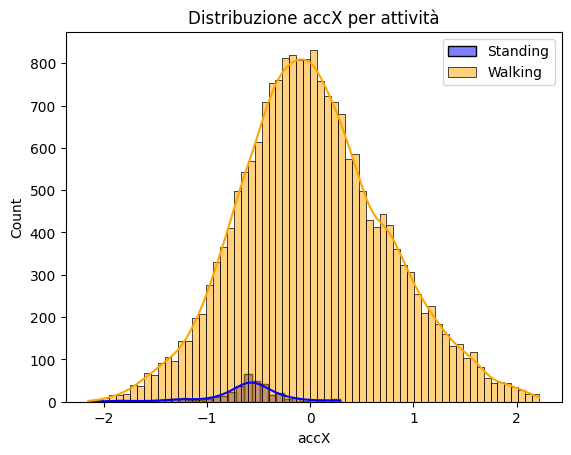

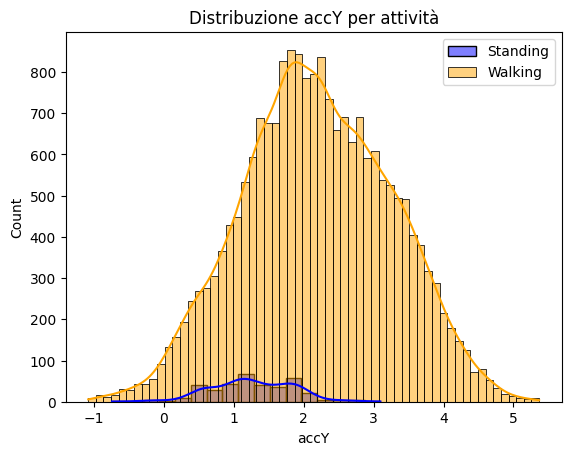

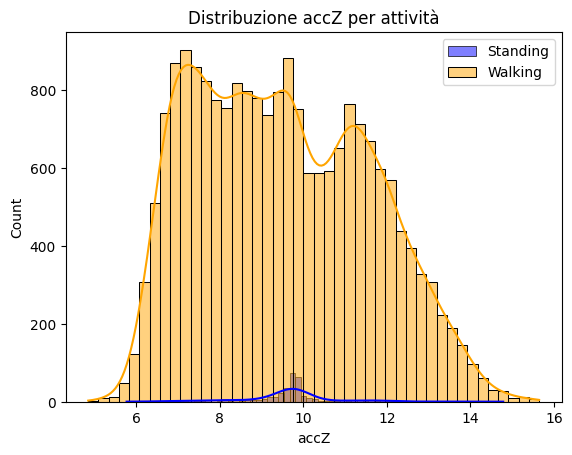

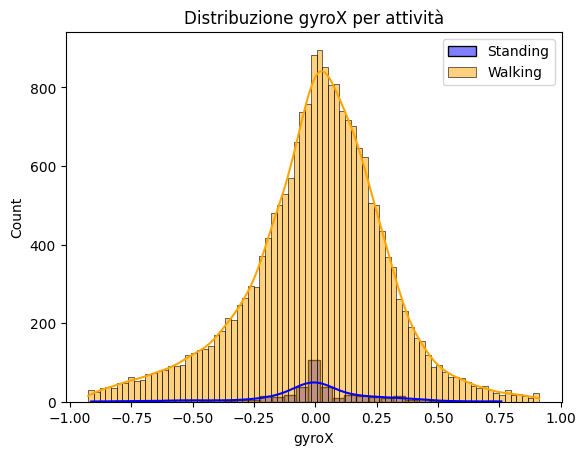

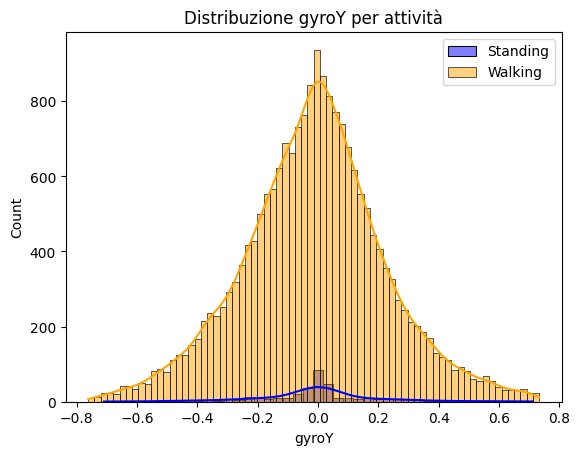

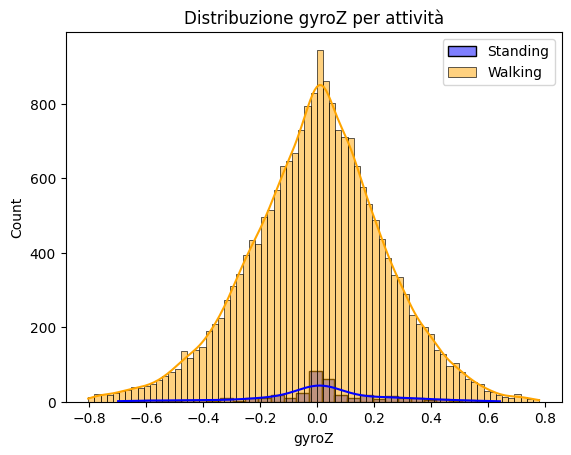

In [ ]:
all_columns = cleaned_no_outliers_trainset.columns

features = [col for col in all_columns if col != 'Activity']

for feature in features:
  plt.figure() # figsize=(10, 6)
  sns.histplot(cleaned_no_outliers_trainset[cleaned_no_outliers_trainset['Activity'] == 0][feature], kde=True, label='Standing', color='blue')
  sns.histplot(cleaned_no_outliers_trainset[cleaned_no_outliers_trainset['Activity'] == 1][feature], kde=True, label="Walking", color="orange")

  plt.legend()
  plt.title(f"Distribuzione {feature} per attività")
  plt.show()

In [ ]:
# Function to design a high-pass filter (Butterworth filter)
def butter_highpass(cutoff, fs, order=4):
    nyquist = 0.5 * fs  # Nyquist frequency
    normal_cutoff = cutoff / nyquist  # Normalize the cutoff frequency
    b, a = butter(order, normal_cutoff, btype='high', analog=False)
    return b, a

# Function for high-pass filter the data
def highpass_filter(data, cutoff, fs, order=4):
    b, a = butter_highpass(cutoff, fs, order)
    return filtfilt(b, a, data)  # Apply the filter (zero-phase filtering)

# Parameters for the high-pass filter
fs = 50  # Sampling frequency (Hz)
cutoff = 0.1  # Cutoff frequency for the high-pass filter (Hz)

# Apply high-pass filter to the gyro data (gyroX, gyroY, gyroZ)
gyroX_filtered = highpass_filter(cleaned_no_outliers_trainset['gyroX'].values, cutoff, fs)
gyroY_filtered = highpass_filter(cleaned_no_outliers_trainset['gyroY'].values, cutoff, fs)
gyroZ_filtered = highpass_filter(cleaned_no_outliers_trainset['gyroZ'].values, cutoff, fs)

cleaned_no_outliers_trainset['gyroX'] = gyroX_filtered
cleaned_no_outliers_trainset['gyroY'] = gyroY_filtered
cleaned_no_outliers_trainset['gyroZ'] = gyroZ_filtered

In [ ]:
# Function to design a low-pass filter
def butter_lowpass(cutoff, fs, order=4):
    nyquist = 0.5 * fs  # Nyquist frequency
    normal_cutoff = cutoff / nyquist  # Normalize the cutoff frequency
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

# Function for low-pass filter the data
def lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order)
    return filtfilt(b, a, data)  # Apply the filter (zero-phase filtering)

lowpass_cutoff = 5.0  # Cutoff frequency for low-pass filter (Hz)

accX_lowpass = lowpass_filter(cleaned_no_outliers_trainset['accX'].values, lowpass_cutoff, fs)
accY_lowpass = lowpass_filter(cleaned_no_outliers_trainset['accY'].values, lowpass_cutoff, fs)
accZ_lowpass = lowpass_filter(cleaned_no_outliers_trainset['accZ'].values, lowpass_cutoff, fs)

cleaned_no_outliers_trainset['accX'] = accX_lowpass
cleaned_no_outliers_trainset['accY'] = accY_lowpass
cleaned_no_outliers_trainset['accZ'] = accZ_lowpass

# FEATURE ENGINEERING



## Augmentation del training set: SMOTE

In [ ]:
# Aggiunta di rumore
def add_noise(data, noise_level=0.01):
    noise = noise_level * np.random.normal(size=data.shape)
    return data + noise

# SMOTE
X = cleaned_no_outliers_trainset.drop(columns=['Activity'])  # Features (tutte le colonne tranne le etichette)
y = cleaned_no_outliers_trainset['Activity']                # Etichette (colonna 'Activity')

# SMOTE per oversampling della classe minoritaria
smote = SMOTE(sampling_strategy=0.5, k_neighbors=3, random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Sottocampionamento della classe maggioritaria
#undersampler = RandomUnderSampler()
#X_resampled, y_resampled = undersampler.fit_resample(X_resampled, y_resampled)

#undersampler = ClusterCentroids(random_state=42)
#X_resampled, y_resampled = undersampler.fit_resample(X_resampled, y_resampled)

# Fusione tra il dataset originale e i dati creati aggiungendo il rumore
X_resampled_df = pd.DataFrame(X_resampled, columns=X.columns)  # Mantenere i nomi delle colonne
y_resampled_df = pd.DataFrame(y_resampled, columns=['Activity'])  # Etichetta come DataFrame

# Combina features e etichette del dataset resampled
augmented_train_set = pd.concat([X_resampled_df, y_resampled_df], axis=1) # resampled_data

# Fondi il dataset resampled con il dataset originale
#augmented_train_set = pd.concat([cleaned_no_outliers_trainset, resampled_data])

# Rimuovi eventuali duplicati (opzionale)
augmented_train_set = augmented_train_set.drop_duplicates()

print("Lunghezza del training set dopo aver aumentato la sua grandezza con SMOTE e ridotto la classe maggioritaria con undersampling: " + str(len(augmented_train_set)) + " elementi.")

Lunghezza del training set dopo aver aumentato la sua grandezza con SMOTE e ridotto la classe maggioritaria con undersampling: 30429 elementi.


In [ ]:
out_of_bounds = augmented_train_set[
    (augmented_train_set['accX'] < -1.5) | (augmented_train_set['accX'] > 1.5) |
    (augmented_train_set['accY'] < 0.0) | (augmented_train_set['accY'] > 4.0) |
    (augmented_train_set['accZ'] < 6) | (augmented_train_set['accZ'] > 14)
]

if not out_of_bounds.empty:
    print("Valori fuori dai limiti trovati:")
    print(out_of_bounds.size)
else:
    print("Tutti i valori sono entro i limiti specificati.")

Tutti i valori sono entro i limiti specificati.


In [ ]:
augmented_train_set_clean = augmented_train_set[
    (augmented_train_set['accX'] >= -1.5) & (augmented_train_set['accX'] <= 1.5) &
    (augmented_train_set['accY'] >= 0.0) & (augmented_train_set['accY'] <= 4.0) &
    (augmented_train_set['accZ'] >= 6) & (augmented_train_set['accZ'] <= 14)
]

# Verifica se ci sono ancora valori fuori dai limiti
out_of_bounds_clean = augmented_train_set_clean[
    (augmented_train_set_clean['accX'] < -1.5) | (augmented_train_set_clean['accX'] > 1.5) |
    (augmented_train_set_clean['accY'] < 0.0) | (augmented_train_set_clean['accY'] > 4.0) |
    (augmented_train_set_clean['accZ'] < 6) | (augmented_train_set_clean['accZ'] > 14)
]

if not out_of_bounds_clean.empty:
    print("Valori fuori dai limiti trovati ancora dopo la pulizia:")
    print(out_of_bounds_clean)
else:
    print("Tutti i valori ora sono entro i limiti specificati.")


Tutti i valori ora sono entro i limiti specificati.


In [ ]:
print("Valori fuori dai limiti: ", out_of_bounds_clean.size)

Valori fuori dai limiti:  0


### SALVO IL TRAINSET SU FILE

In [ ]:
augmented_train_set_clean.to_csv('augmented_train_set_clean.csv', index=False)

In [ ]:
augmented_train_set = pd.read_csv('augmented_train_set_clean.csv')

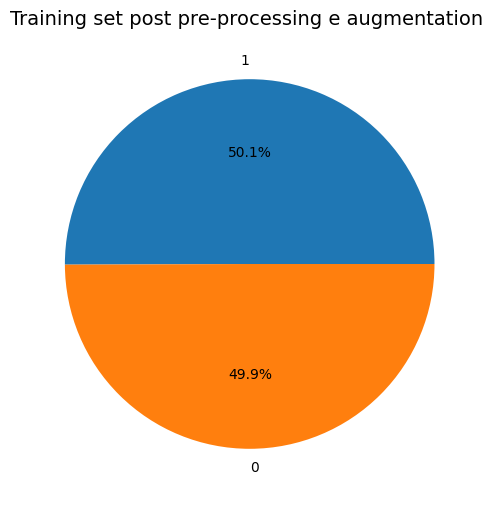

In [ ]:
plot_pie_values_col(ds=augmented_train_set, column="Activity", title="Training set post pre-processing e augmentation ")

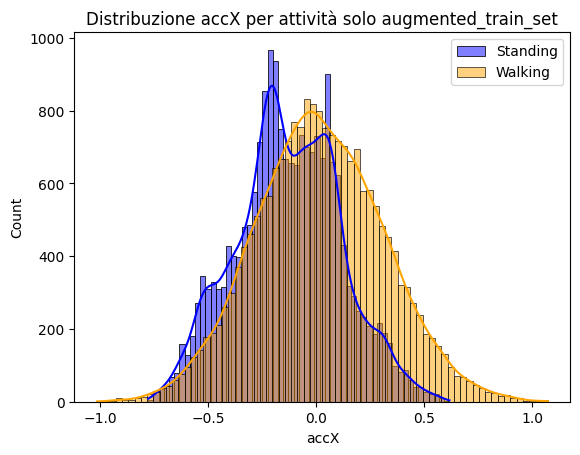

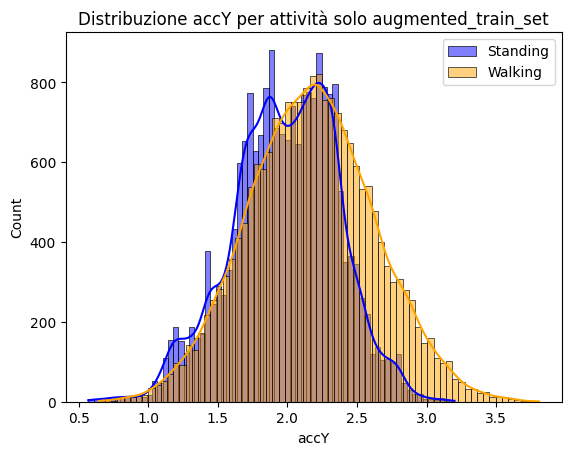

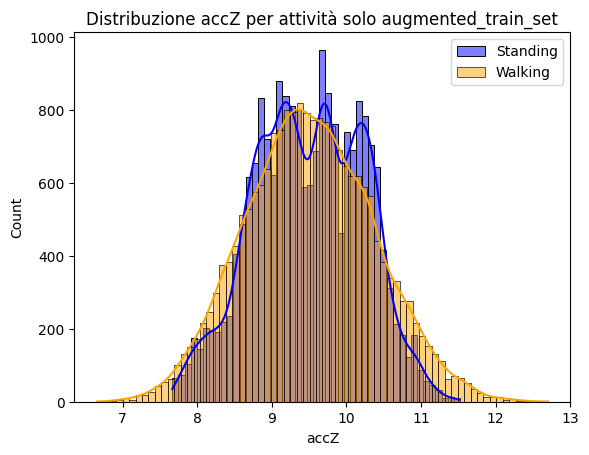

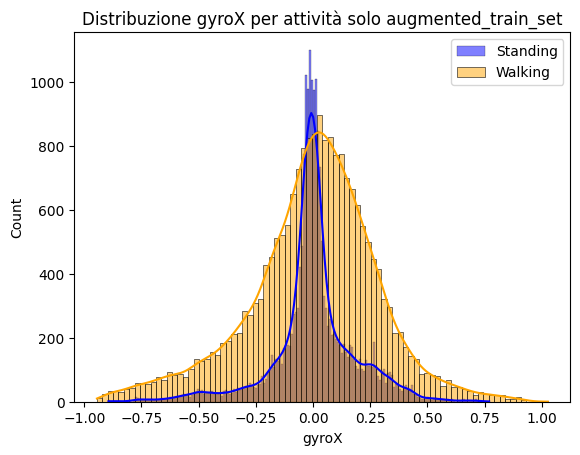

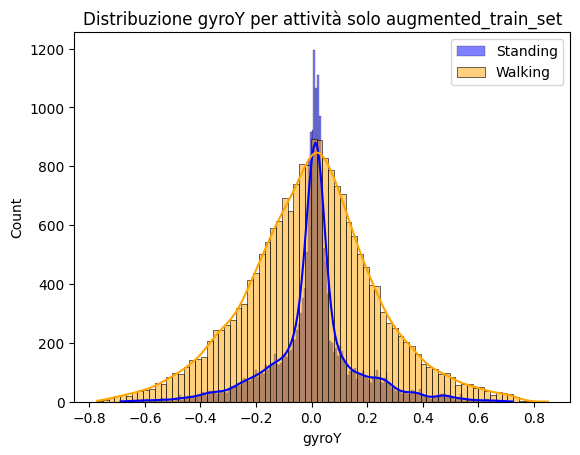

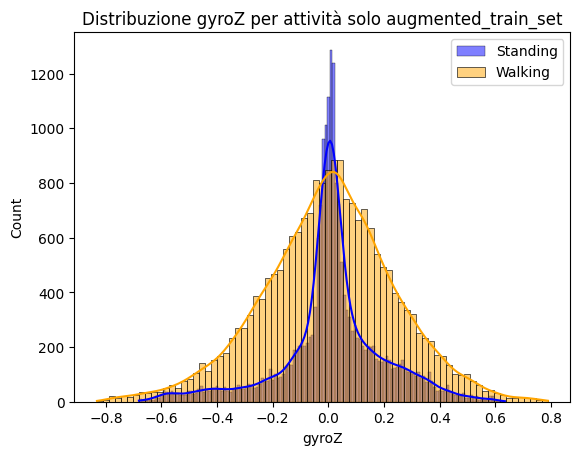

In [ ]:
all_columns = augmented_train_set.columns

features = [col for col in all_columns if col != 'Activity']

for feature in features:
  plt.figure() # figsize=(10, 6)
  sns.histplot(augmented_train_set[augmented_train_set['Activity'] == 0][feature], kde=True, label='Standing', color='blue')
  sns.histplot(augmented_train_set[augmented_train_set['Activity'] == 1][feature], kde=True, label="Walking", color="orange")

  plt.legend()
  plt.title(f"Distribuzione {feature} per attività solo augmented_train_set")
  plt.show()

## Classification Pipeline Definition

In [ ]:
# Separazione delle feature (X) e target (y) PRIMA della standardizzazione
X_train = augmented_train_set.drop(columns=['Activity'])  # Rimuove la colonna target
y_train = augmented_train_set['Activity']  # Target

X_val = val_set.drop(columns=['Activity'])
y_val = val_set['Activity']

X_test = test_set.drop(columns=['Activity'])
y_test = test_set['Activity']

numerical_features = X_train.columns.tolist()

# Creazione della pipeline --> evita implicitamente il data leakage
numeric_transformer_pipeline = Pipeline([
    ('scaler', StandardScaler())
])

# Creazione di ColumnTransformer per il preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_pipeline, numerical_features),
    ]
)

# Creazione della final pipeline
final_pipeline = Pipeline([
    ('preprocessor', preprocessor),  # Step di preprocessing
    ('classifier', SVC())  # Modello iniziale
])

In [ ]:
preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('scaler', StandardScaler())]),
                                 ['accX', 'accY', 'accZ', 'gyroX', 'gyroY',
                                  'gyroZ'])])

# HyperParameter Tuning and Training ML Models
Tuning iperparametri mediante Optuna, Grid Search e Random Search.

## GRID SEARCH

In [ ]:
# Define random state
RANDOM_STATE = 42

# Definizione dei modelli e iperparametri per Grid Search
param_grids = {
    'RandomForest': {
        'model': RandomForestClassifier(random_state=RANDOM_STATE),
        'params': {
            'classifier__n_estimators': [50, 100],
            'classifier__max_depth': [None, 10],
            'classifier__min_samples_split': [2, 5, 10],
            'classifier__min_samples_leaf': [1, 2, 4],
            'classifier__max_features': ['sqrt', 'log2']
        }
    },
    'ExtraTrees': {
        'model': ExtraTreesClassifier(random_state=RANDOM_STATE),
        'params': {
            'classifier__n_estimators': [50, 100],
            'classifier__max_depth': [None, 10],
            'classifier__min_samples_split': [2, 5, 10],
            'classifier__min_samples_leaf': [1, 2, 4],
            'classifier__max_features': ['sqrt', 'log2']
        }
    }
}

# Create StratifiedKFold
cross_validation = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# Scoring metrics
SCORING = {"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy",  "f2": make_scorer(fbeta_score, beta=2)}

# Fit GridSearchCV for each classifier and save the best model
best_models = {}

# Grid Search con parallelizzazione
with parallel_backend('loky', n_jobs=-1):
    for model_name, model_info in param_grids.items():
        print(f"\nGridSearchCV per {model_name}...")

        # Creazione della pipeline con il modello specificato
        final_pipeline.set_params(classifier=model_info['model'])

        grid_search = GridSearchCV(
            estimator=final_pipeline,
            param_grid=model_info['params'],
            cv=cross_validation,
            verbose=1,
            scoring="accuracy",  # Imposta una sola metrica di valutazione, ad esempio "accuracy"
            return_train_score=True,
            n_jobs=-1,  # Utilizza tutti i core disponibili
            refit="accuracy"  # Seleziona il modello migliore in base all'accuracy
        )


        grid_search.fit(X_train, y_train)

        best_model = grid_search.best_estimator_
        y_pred = best_model.predict(X_test) # X_test è già scalato dentro la pipeline
        accuracy = accuracy_score(y_test, y_pred)

        # Salvataggio risultati
        best_models[model_name] = {
            'best_params': grid_search.best_params_,
            'accuracy': accuracy
        }

# Output risultati
for model_name, result in best_models.items():
    print(f"{model_name}:")
    print(f"  Migliori parametri: {result['best_params']}")
    print(f"  Accuratezza: {result['accuracy']:.4f}")



GridSearchCV per RandomForest...
Fitting 3 folds for each of 72 candidates, totalling 216 fits

GridSearchCV per ExtraTrees...
Fitting 3 folds for each of 72 candidates, totalling 216 fits
RandomForest:
  Migliori parametri: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
  Accuratezza: 0.9780
ExtraTrees:
  Migliori parametri: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
  Accuratezza: 0.9797


In [ ]:
# Salva il modello migliore su un file
best_model_filename = "best_model_grid_search.pkl"
joblib.dump(best_model, best_model_filename)

print(f"Modello salvato come {best_model_filename}")

Modello salvato come best_model_grid_search.pkl


In [ ]:
log_file = "best_models_grid_search.log"

with open(log_file, "w") as f:
    for model_name, result in best_models.items():
        f.write(f"{model_name}:\n")
        f.write(f"  Migliori parametri: {result['best_params']}\n")
        f.write(f"  Accuratezza: {result['accuracy']:.4f}\n")

print(f"Results saved to {log_file}")

Results saved to best_models_grid_search.log


## Random Search

In [ ]:
# Define random state
RANDOM_STATE = 42

# 2. Definizione dei modelli e delle distribuzioni degli iperparametri
param_distributions = {
    'RandomForest': {
        'model': RandomForestClassifier(random_state=RANDOM_STATE),
        'params': {
            'classifier__n_estimators': [50, 100, 200],
            'classifier__max_depth': [None, 10, 20],
            'classifier__min_samples_split': [2, 5, 10, 15],
            'classifier__min_samples_leaf': [1, 2, 4, 6],
            'classifier__max_features': ['sqrt', 'log2'],
            'classifier__class_weight': ['balanced']
        }
    },
    'ExtraTrees': {
        'model': ExtraTreesClassifier(random_state=RANDOM_STATE),
        'params': {
            'classifier__n_estimators': [50, 100, 200],
            'classifier__max_depth': [None, 10],
            'classifier__min_samples_split': [2, 5, 10, 15],
            'classifier__min_samples_leaf': [1, 2, 4, 6],
            'classifier__max_features': ['sqrt', 'log2'],
            'classifier__class_weight': ['balanced']
        }
    }
}


# Create StratifiedKFold
cross_validation = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# Scoring metrics
SCORING = {"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy", "f2": make_scorer(fbeta_score, beta=2)}

# Fit RandomSearchCV for each classifier and save the best model
best_models_random_search = {}

# 4. RandomizedSearchCV per ciascun modello
# Random Search con parallelizzazione

with parallel_backend('loky', n_jobs=-1):
    for model_name, model_info in param_distributions.items():
        print(f"\RandomizedSearchCV per {model_name}...")

        total_param_combinations = sum(1 for _ in ParameterSampler(model_info['params'], n_iter=1000)) # `n_iter=1000` è solo un valore arbitrariamente alto
        # per assicurarsi di contare tutte le combinazioni possibili. Non influisce sulla ricerca vera e propria, serve solo per calcolare `total_param_combinations`.

        # Creazione della pipeline con il modello specificato
        final_pipeline.set_params(classifier=model_info['model'])

        random_search = RandomizedSearchCV(
            estimator=final_pipeline,
            param_distributions=model_info['params'],
            n_iter = min(10, total_param_combinations),
            cv=cross_validation,
            verbose=1,
            scoring="accuracy",  # Imposta una sola metrica di valutazione, ad esempio "accuracy"
            return_train_score=True,
            n_jobs=-1,  # Utilizza tutti i core disponibili
            refit="accuracy"  # Seleziona il modello migliore in base all'accuracy
        )


        random_search.fit(X_train, y_train)

        best_model = random_search.best_estimator_
        y_pred = best_model.predict(X_test) # X_test è già scalato dentro la pipeline
        accuracy = accuracy_score(y_test, y_pred)

        # Salvataggio risultati
        best_models_random_search[model_name] = {
            'best_params': random_search.best_params_,
            'accuracy': accuracy
        }

# Output risultati
for model_name, result in best_models_random_search.items():
    print(f"{model_name}:")
    print(f"  Migliori parametri: {result['best_params']}")
    print(f"  Accuratezza: {result['accuracy']:.4f}")


\RandomizedSearchCV per RandomForest...
Fitting 3 folds for each of 10 candidates, totalling 30 fits


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 288 is smaller than n_iter=1000. Running 288 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


\RandomizedSearchCV per ExtraTrees...
Fitting 3 folds for each of 10 candidates, totalling 30 fits


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 192 is smaller than n_iter=1000. Running 192 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


RandomForest:
  Migliori parametri: {'classifier__n_estimators': 200, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt', 'classifier__max_depth': None, 'classifier__class_weight': 'balanced'}
  Accuratezza: 0.9788
ExtraTrees:
  Migliori parametri: {'classifier__n_estimators': 100, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'log2', 'classifier__max_depth': None, 'classifier__class_weight': 'balanced'}
  Accuratezza: 0.9759


In [ ]:
log_file = "best_models_random_search.log"

with open(log_file, "w") as f:
    for model_name, result in best_models_random_search.items():
        f.write(f"{model_name}:\n")
        f.write(f"  Migliori parametri: {result['best_params']}\n")
        f.write(f"  Accuratezza: {result['accuracy']:.4f}\n")

print(f"Results saved to {log_file}")


Results saved to best_models_random_search.log


In [ ]:
# Salva il modello migliore su un file
best_model_filename_random_search = "best_model_random_search.pkl"
joblib.dump(best_models_random_search, best_model_filename_random_search)

print(f"Accuracy after Random Search: {accuracy:.4f}")

Accuracy after Random Search: 0.9759


In [ ]:
loaded_model = joblib.load("best_model_random_search.pkl")

best_model_name = max(loaded_model, key=lambda x: loaded_model[x]['accuracy'])

# modello sklearn e accuracy del best model
best_model = loaded_model[best_model_name]
best_accuracy = loaded_model[best_model_name]['accuracy']

print(f"Il miglior modello è: {best_model_name} --> {best_model}")

Il miglior modello è: RandomForest --> {'best_params': {'classifier__n_estimators': 200, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt', 'classifier__max_depth': None, 'classifier__class_weight': 'balanced'}, 'accuracy': 0.9787838605796553}


## OPTUNA

In [ ]:
RANDOM_STATE = 42069
TEST_SIZE = 0.33
INTER_OPS = 0  # Independent non-blocking operations.
INTRA_OPS = 0  # Internal Matrix multiplication and reductions.

tf.config.threading.set_inter_op_parallelism_threads(INTER_OPS)
tf.config.threading.set_intra_op_parallelism_threads(INTRA_OPS)
tf.device('/GPU:0')

np.random.seed(seed=RANDOM_STATE)
tf.random.set_seed(seed=RANDOM_STATE)
random.seed(RANDOM_STATE)

In [ ]:
def save_best_model_callback(study, trial):
    if study.best_trial.number == trial.number:
      study.set_user_attr(key="best_model", value=trial.user_attrs["best_model"])

In [ ]:
def multi_stratified_kfold(X_train, y_train):
    skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

    folds = list(skf.split(X_train, y_train))  # Just the indices
    return folds

Questa implementazione utilizza la funzione multi_stratified_kfold per generare i fold di allenamento e validazione. La funzione objective addestra il modello su ciascun fold e calcola il punteggio medio per determinare l'efficacia del modello. (vedi i Colab indicati sopra)

In [ ]:
best_models = {}

# Objective function for Optuna
def objective(trial, cv):
    classifier_name = trial.suggest_categorical(
        'classifier', ['RandomForest', 'ExtraTrees']
    )

    if classifier_name == 'RandomForest':
        rf_n_estimators = trial.suggest_int('rf_n_estimators', 200, 210)
        #rf_n_estimators = 200,
        classifier = RandomForestClassifier(n_estimators=rf_n_estimators, min_samples_split=2, min_samples_leaf=1, max_features='sqrt', class_weight='balanced', max_depth=None)

    else:
        et_n_estimators = trial.suggest_int('et_n_estimators', 100, 110)
        #et_n_estimators = 50,
        classifier = ExtraTreesClassifier(n_estimators=et_n_estimators, min_samples_split=10, min_samples_leaf=2, max_features='log2', class_weight='balanced', max_depth=None)

    # Replace classifier in the pipeline
    pipeline = clone(final_pipeline)
    pipeline.steps[-1] = ('classifier', classifier)

    # Cross-validation evaluation
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='accuracy')
    avg_score = np.mean(scores)

    # Save the best model for this classifier
    if classifier_name not in best_models or best_models[classifier_name]['score'] < avg_score:
        best_models[classifier_name] = {
            'params': trial.params,
            'score': avg_score
        }

    return avg_scoremail


In [ ]:
# print("Miglior modello:", study.best_trial.params)

In [ ]:
study_name = "mldm-project-study"
study_path = "./optuna.log"
storage_name = JournalStorage(JournalFileBackend(study_path))
mskfolds = multi_stratified_kfold(X_train, y_train)
study = optuna.create_study(
    direction="maximize",
    study_name=study_name,
    storage=storage_name,
    load_if_exists=True,
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
    pruner=optuna.pruners.SuccessiveHalvingPruner()
)

optuna.logging.set_verbosity(optuna.logging.DEBUG)

[I 2025-04-03 17:49:59,573] A new study created in Journal with name: mldm-project-study


In [ ]:
def delete_init_model_weights_callback(study, trial):
    """Callback that removes initial weights of unoptimal models"""
    if study.best_trial.number != trial.number:
        if "init_weights_pathname" in trial.user_attrs:
            os.remove(trial.user_attrs["init_weights_pathname"])

In [ ]:
# Create Optuna Study
study.optimize(lambda trial: objective(trial, cv=mskfolds), n_trials=20, n_jobs=-1,gc_after_trial=True, callbacks=[delete_init_model_weights_callback])

# Print Best Models for Each Classifier
for model_name, details in best_models.items():
    print(f"Best model for {model_name}:")
    print(f"  Max Score: {details['score']}")
    print(f"  Parameters: {details['params']}")

[I 2025-04-03 17:50:44,436] Trial 0 finished with value: 0.9642699130401742 and parameters: {'classifier': 'ExtraTrees', 'et_n_estimators': 110}. Best is trial 0 with value: 0.9642699130401742.
[I 2025-04-03 17:57:24,359] Trial 1 finished with value: 0.9727829238892667 and parameters: {'classifier': 'RandomForest', 'rf_n_estimators': 204}. Best is trial 1 with value: 0.9727829238892667.
[I 2025-04-03 17:58:11,963] Trial 3 finished with value: 0.9640478248596033 and parameters: {'classifier': 'ExtraTrees', 'et_n_estimators': 109}. Best is trial 1 with value: 0.9727829238892667.
[I 2025-04-03 17:58:23,504] Trial 2 finished with value: 0.9732764585919684 and parameters: {'classifier': 'RandomForest', 'rf_n_estimators': 208}. Best is trial 2 with value: 0.9732764585919684.
[I 2025-04-03 17:58:59,434] Trial 4 finished with value: 0.9639737934363757 and parameters: {'classifier': 'ExtraTrees', 'et_n_estimators': 104}. Best is trial 2 with value: 0.9732764585919684.
[I 2025-04-03 17:59:41,437

Best model for ExtraTrees:
  Max Score: 0.9642699130401742
  Parameters: {'classifier': 'ExtraTrees', 'et_n_estimators': 110}
Best model for RandomForest:
  Max Score: 0.973745332391226
  Parameters: {'classifier': 'RandomForest', 'rf_n_estimators': 205}


In [ ]:
print("Miglior modello:", study.best_trial.params)

Miglior modello: {'classifier': 'RandomForest', 'rf_n_estimators': 205}


Visualizzazione Optuna study

In [ ]:
print(best_models)

{'ExtraTrees': {'params': {'classifier': 'ExtraTrees', 'et_n_estimators': 110}, 'score': np.float64(0.9642699130401742)}, 'RandomForest': {'params': {'classifier': 'RandomForest', 'rf_n_estimators': 205}, 'score': np.float64(0.973745332391226)}}


In [ ]:
print(study.best_trial.number)
print(study.best_params)
print(study.best_value)

# Save the file in the current working directory
with open("/content/mldm-project-optuna-study.log", "w") as f:
  for model_name, result in best_models.items():
    f.write(f"Best model for {model_name}:\n")
    f.write(f"Max Score: {result['score']}\n")
    f.write(f"Parameters: {result['params']}\n\n")

  f.write(f"Miglior trial: {study.best_trial.number}\n")
  f.write(f"Migliori parametri in assoluto: {study.best_params}\n")
  f.write(f"Miglior valore in assoluto: {study.best_value}")

10
{'classifier': 'RandomForest', 'rf_n_estimators': 205}
0.973745332391226


<ipython-input-74-471f79a759ba>:1: ExperimentalWarning: plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(study)


<Axes: title={'center': 'Optimization History Plot'}, xlabel='Trial', ylabel='Objective Value'>

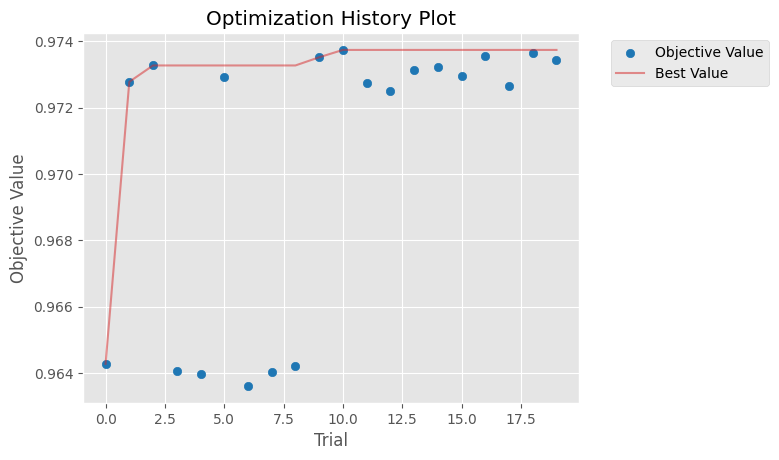

In [ ]:
optuna.visualization.matplotlib.plot_optimization_history(study)

<ipython-input-75-ac243543a9b5>:1: ExperimentalWarning: plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_slice(study)


array([<Axes: xlabel='classifier', ylabel='Objective Value'>,
       <Axes: xlabel='et_n_estimators'>, <Axes: xlabel='rf_n_estimators'>],
      dtype=object)

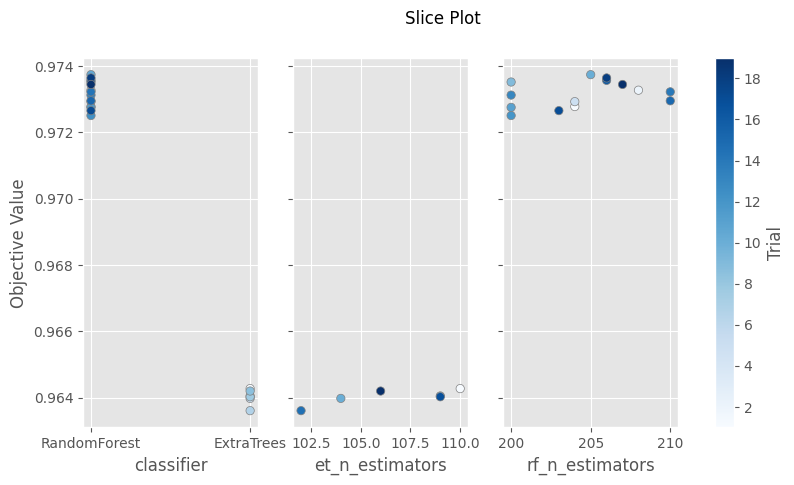

In [ ]:
optuna.visualization.matplotlib.plot_slice(study)

<ipython-input-76-a5c7740d20da>:1: ExperimentalWarning: plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_param_importances(study)


<Axes: title={'left': 'Hyperparameter Importances'}, xlabel='Hyperparameter Importance', ylabel='Hyperparameter'>

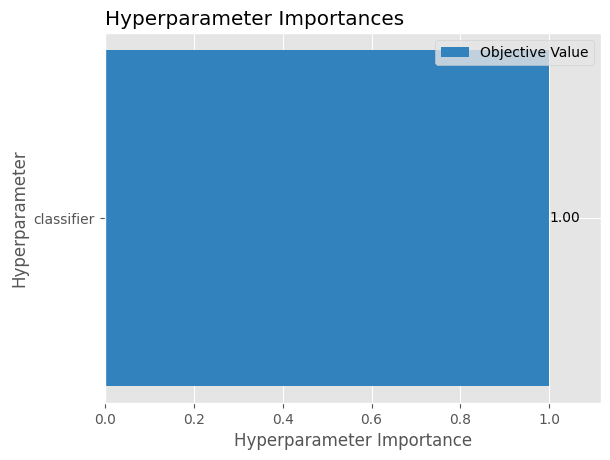

In [ ]:
optuna.visualization.matplotlib.plot_param_importances(study)

In [ ]:
# Estrazione del miglior trial (il migliore modello ottimizzato)
best_trial = study.best_trial

# Miglior modello individuato (il modello con i parametri ottimizzati)
best_classifier_params = best_trial.params

# Training con il miglior modello individuato da Optuna

###   Pipeline Training

In [ ]:
# recupero il nome del modello
model_name = best_classifier_params.pop("classifier")

In [ ]:
# Dizionario per mappare i nomi alle corrispondenti classi dei modelli - inserisco tutti quelli usati
model_classes = {
    "SVC_linear": sklearn.svm.SVC(kernel="linear"),
    "SVC_rbf": sklearn.svm.SVC(kernel="rbf"),
    "RandomForest": sklearn.ensemble.RandomForestClassifier,
    "GradientBoostingClassifier": sklearn.ensemble.GradientBoostingClassifier,
    "XGBClassifier": xgboost.XGBClassifier,  # XGBoost
    "LogisticRegression": sklearn.linear_model.LogisticRegression,
    "AdaBoostClassifier": sklearn.ensemble.AdaBoostClassifier,
    "ExtraTrees": sklearn.ensemble.ExtraTreesClassifier,
    "KNeighborsClassifier": sklearn.neighbors.KNeighborsClassifier,
}

# Scelta del kernel corretto  ==> recupero kernel corretto da best_classifir_params
if "SVC" in model_name:
    kernel_type = best_classifier_params.pop("kernel_type", "linear")  # recupero il tipo di kernel
    model_classes[model_name] = sklearn.svm.SVC(kernel=kernel_type)  # Imposta il kernel corretto per distinguere tra SVC_linear e SVC_rbf



In [ ]:
# Rimuove eventuali prefissi noti (es. "et_", "rf_", "gb_" ecc.)
prefixes_to_remove = ["et_", "rf_", "gb_", "xgb_"]  # Aggiungi altri se necessario

# Pulizia dei parametri rimuovendo eventuali prefissi
clean_params = {
    k.lstrip("_".join(prefix for prefix in prefixes_to_remove if k.startswith(prefix))): v
    for k, v in best_classifier_params.items()
}

# Parametri da forzare per migliorare il bilanciamento e la riproducibilità
forced_params = {
    "class_weight": "balanced",
    "min_samples_split": 2,
    "min_samples_leaf": 1,
    "max_features": "sqrt",
    "max_depth": None,
    "random_state": 42
}

# Aggiunta dei parametri forzati, senza sovrascrivere quelli già presenti in `best_classifier_params`
for param, value in forced_params.items():
    clean_params.setdefault(param, value)  # Usa solo se il parametro non è già presente

# Se il modello supporta `n_estimators`, aggiungilo (utile per ExtraTrees e RandomForest)
if "n_estimators" in model_classes[model_name]().get_params():
    clean_params.setdefault("n_estimators", 205)  # Modifica se necessario (es. 200 per RandomForest)

# Ricrea il miglior classificatore con i parametri puliti
best_classifier = model_classes[model_name](**clean_params)

# Clonare la pipeline esistente per evitare di modificare l'originale
best_pipeline = clone(final_pipeline)

# Sostituire l'ultimo step (il classificatore) con quello nuovo
best_pipeline.steps[-1] = ('classifier', best_classifier)

# Verifica finale
print(f"Pipeline aggiornata con il miglior modello: {model_name}")
print(f"Parametri finali: {best_classifier.get_params()}")

Pipeline aggiornata con il miglior modello: RandomForest
Parametri finali: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 205, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [ ]:
# classifier = RandomForestClassifier(n_estimators=rf_n_estimators, min_samples_split=5, min_samples_leaf=1, max_features='sqrt', class_weight='balanced', max_depth=20)
# classifier = ExtraTreesClassifier(n_estimators=et_n_estimators, min_samples_split=2, min_samples_leaf=1, max_features='log2', class_weight='balanced', max_depth=None)
best_pipeline = clone(final_pipeline)
#best_pipeline.steps[-1] = ('classifier', ExtraTreesClassifier(n_estimators=55, min_samples_split=2, min_samples_leaf=1, max_features='log2', class_weight='balanced', max_depth=None, random_state=42))
best_pipeline.steps[-1] = ('classifier', RandomForestClassifier(n_estimators=205, min_samples_split=2, min_samples_leaf=1, max_features='sqrt', class_weight='balanced', max_depth=None))

In [ ]:
best_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['accX', 'accY', 'accZ',
                                                   'gyroX', 'gyroY',
                                                   'gyroZ'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=205))])

In [ ]:
# Ri-definizione del training set (train_set "+" val_set)

# Concateno le feature xi
X_train_final = pd.concat([X_train, X_val], ignore_index=True)

# Concateno le etichette/label/classi yi
y_train_final = pd.concat([y_train, y_val], ignore_index=True)

print(f"Dimensione X_train_final: {X_train_final.shape}")
print(f"Dimensione y_train_final: {y_train_final.shape}")

Dimensione X_train_final: (45805, 6)
Dimensione y_train_final: (45805,)


In [ ]:
# TRAINING - Fit the best model (pipeline with std scaler) with X_train data
best_pipeline.fit(X_train_final, y_train_final)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['accX', 'accY', 'accZ',
                                                   'gyroX', 'gyroY',
                                                   'gyroZ'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=205))])

### Pipeline Saving

In [ ]:
# Save the classification pipeline to a file using joblib
joblib.dump(best_pipeline, "classification_pipeline.joblib")

['classification_pipeline.joblib']

### Pipeline Reloading

In [ ]:
# Load the classification pipeline from a file using joblib
classification_pipeline=joblib.load("classification_pipeline.joblib")

## CNN

In [ ]:
data_reshaped = np.array(X_train)
data_reshaped = data_reshaped.T
data_reshaped = np.expand_dims(data_reshaped, axis=-1)

# Creazione del modello
model = Sequential()
model.add(Conv1D(64, kernel_size=3, activation='relu', input_shape=(data_reshaped.shape[1], data_reshaped.shape[2]), padding='SAME'))
model.add(MaxPooling1D(pool_size=1))
model.add(Conv1D(128, kernel_size=3, activation='relu', padding='SAME'))
model.add(MaxPooling1D(pool_size=1))
model.add(Conv1D(256, kernel_size=3, activation='relu', padding='SAME'))
model.add(MaxPooling1D(pool_size=1))
model.add(Conv1D(512, kernel_size=3, activation='relu', padding='SAME'))
model.add(GlobalMaxPooling1D())
model.add(Dense(256, activation='relu'))
model.add(Dense(1, activation='sigmoid'))  # Binary classification

# Compilo il modello
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_16 (Conv1D)                   │ (None, 40519, 64)           │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_12 (MaxPooling1D)      │ (None, 40519, 64)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_17 (Conv1D)                   │ (None, 40519, 128)          │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_13 (MaxPooling1D)      │ (None, 40519, 128)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_18 (Conv1D)                   │ (None, 40519, 256)          │          98,560 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_14 (MaxPooling1D)      │ (None, 40519, 256)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_19 (Conv1D)                   │ (None, 40519, 512)          │         393,728 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_max_pooling1d_4               │ (None, 512)                 │               0 │
│ (GlobalMaxPooling1D)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 1)                   │             257 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 648,833 (2.48 MB)

 Trainable params: 648,833 (2.48 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# EarlyStopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Fit del modello
hst = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_val, y_val), callbacks=[early_stopping])

Epoch 1/50
1267/1267 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.6326 - loss: 0.6113 - val_accuracy: 0.6246 - val_loss: 0.6366
Epoch 2/50
1267/1267 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7348 - loss: 0.5216 - val_accuracy: 0.7731 - val_loss: 0.4490
Epoch 3/50
1267/1267 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7562 - loss: 0.4955 - val_accuracy: 0.8390 - val_loss: 0.3518
Epoch 4/50
1267/1267 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.7731 - loss: 0.4585 - val_accuracy: 0.7806 - val_loss: 0.4217
Epoch 5/50
1267/1267 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7957 - loss: 0.4187 - val_accuracy: 0.8339 - val_loss: 0.3241
Epoch 6/50
1267/1267 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8235 - loss: 0.3780 - val_accuracy: 0.8483 - val_loss: 0.2851
Epoch 7/50
1267/1267 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8446 - loss: 0.3477 - val_accuracy: 0.8666 - val_loss: 0.3024
Epoch 8/50
1267/1267 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8659 - loss: 0.3080 

## Testing - Valutazione Modello



### Pipeline Evaluation

!!! Nota del professore sorta durante la presentazione: regolare la threshold utilizzando il training set e non il testset !!!

In [ ]:
y_probs = best_pipeline.predict_proba(X_test)[:,1]
threshold = 0.895 # "compromesso" tra migliore specificity e f2score
y_pred = (y_probs > threshold).astype(int)

#y_pred = best_pipeline.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
sensitivity = recall  # Sensitivity is the same as recall
specificity = conf_matrix[0, 0] / (conf_matrix[0, 0] + conf_matrix[0, 1])

# F1-score
f1 = f1_score(y_test, y_pred)

f2_score = fbeta_score(y_test, y_pred, beta=2)

# Print performance metrics
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall/Sensitivity: {recall}")
print(f"Specificity: {specificity}")
print(f"Confusion Matrix:\n{conf_matrix}")
print(f"F2-score:\n{f2_score}")

Accuracy: 0.8787649175980299
Precision: 0.9945593035908596
Recall/Sensitivity: 0.8813886210221794
Specificity: 0.7340425531914894
Confusion Matrix:
[[  69   25]
 [ 615 4570]]
F2-score:
0.9019143477402802


In [ ]:
# Prova soglie più alte (es. tra 0.5 e 0.9)
thresholds = np.linspace(0.5, 0.9, 20)
best_threshold = 0
best_specificity = 0

for threshold in thresholds:
    y_pred = (y_probs > threshold).astype(int)
    conf_matrix = confusion_matrix(y_test, y_pred)

    tn, fp, fn, tp = conf_matrix.ravel()
    specificity = tn / (tn + fp)  # Calcola Specificity

    if specificity > best_specificity:
        best_specificity = specificity
        best_threshold = threshold

print(f"🔹 Miglior soglia per Specificity: {best_threshold:.4f}, Specificity: {best_specificity:.4f}")

🔹 Miglior soglia per Specificity: 0.9000, Specificity: 0.7447


### Ricerca soglia ottimale per F2-score

In [ ]:
# Ricerca della soglia ottimale per F2-score

thresholds = np.arange(0.80, 0.87, 0.01)  # Range di soglie
best_f2 = 0
best_thresh = 0.85  # Valore di partenza

for thresh in thresholds:
    y_pred = (y_probs > thresh).astype(int)
    f2 = fbeta_score(y_test, y_pred, beta=2)
    if f2 > best_f2:
        best_f2 = f2
        best_thresh = thresh

print(f"Miglior soglia per F2-score: {best_thresh} con F2-score: {best_f2}")


Miglior soglia per F2-score: 0.8 con F2-score: 0.9575957984827854


In [ ]:
# Calcolo Youden's J statistic per selezionare l'optimal trade-off points
fpr, tpr, thresholds = roc_curve(y_test, y_probs)
youden_index = tpr - fpr
optimal_idx = youden_index.argmax() # maximize youden's index
optimal_threshold = thresholds[optimal_idx]
print(f"Optimal threshold (Youden's J): {optimal_threshold:.4f}")

Optimal threshold (Youden's J): 0.9512


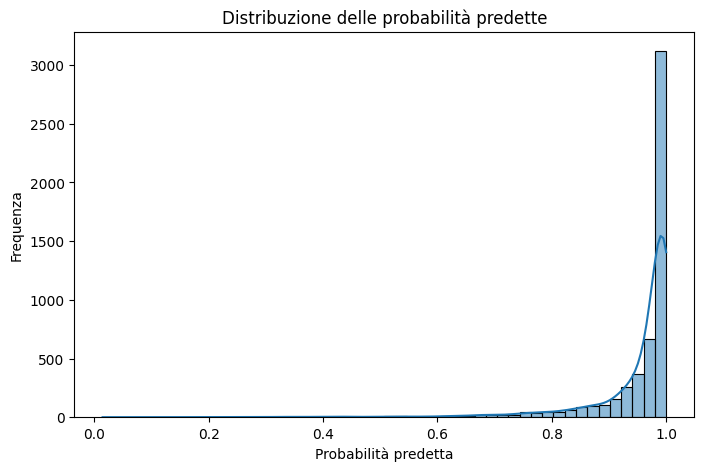

In [ ]:
# plot istogramma delle probabilità predette
plt.figure(figsize=(8,5))
sns.histplot(y_probs, bins=50, kde=True)
plt.xlabel("Probabilità predetta")
plt.ylabel("Frequenza")
plt.title("Distribuzione delle probabilità predette")
plt.show()


Modello sbilanciato verso la classe predominante..

In [ ]:
np.bincount(y_test)

array([  94, 5185])

In [ ]:
log_filename = "best_pipeline_metrics.log"

with open(log_filename, "w") as log_file:
    log_file.write(f"Accuracy: {accuracy}\n")
    log_file.write(f"Precision: {precision}\n")
    log_file.write(f"Recall/Sensitivity: {recall}\n")
    log_file.write(f"Specificity: {specificity}\n")
    log_file.write(f"Confusion Matrix:\n{conf_matrix}\n")
    log_file.write(f"F1-score:\n{f1_score}\n")

print(f"Metrics saved to {log_filename}")

Metrics saved to best_pipeline_metrics.log


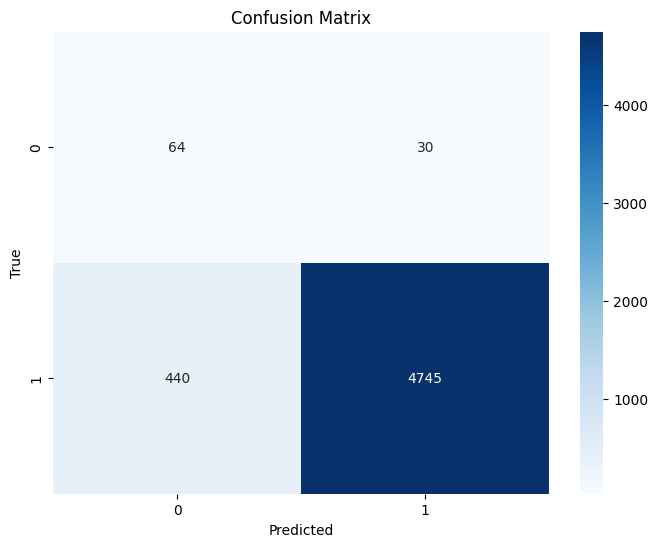

In [ ]:
# Plot confusion_matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=np.unique(y_test),
            yticklabels=np.unique(y_test))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
y_score = best_pipeline.predict_proba(test_set)[:, 1]  # Probabilities for the positive class

In [ ]:
roc_auc_score(y, best_pipeline.predict_proba(X)[:, 1])

np.float64(1.0)

In [ ]:
# Compute ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_score)
# Compute AUC (Area Under the Curve)
roc_auc = auc(fpr, tpr)

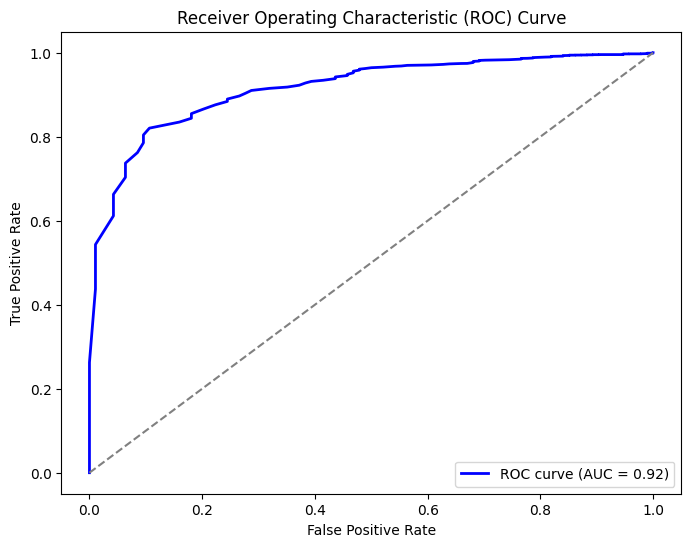

In [ ]:
# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Random classifier line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

#EXTRA TREES

In [ ]:
pipeline_et = clone(final_pipeline)
pipeline_et.steps[-1] = ('classifier', ExtraTreesClassifier(n_estimators=110, min_samples_split=2, min_samples_leaf=1, max_features='sqrt', class_weight='balanced', max_depth=None))

# Ri-definizione del training set (train_set "+" val_set)

# Concateno le feature xi
X_train_final = pd.concat([X_train, X_val])

# Concateno le etichette/label/classi yi
y_train_final = pd.concat([y_train, y_val])

# TRAINING - Fit the best model (pipeline with std scaler) with X_train data
pipeline_et.fit(X_train_final, y_train_final)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['accX', 'accY', 'accZ',
                                                   'gyroX', 'gyroY',
                                                   'gyroZ'])])),
                ('classifier',
                 ExtraTreesClassifier(class_weight='balanced',
                                      n_estimators=110))])

In [ ]:
y_probs_et = pipeline_et.predict_proba(X_test)[:,1]
threshold = 0.895
y_pred_et = (y_probs_et > threshold).astype(int)

#y_pred = best_pipeline.predict(X_test)

accuracy_et = accuracy_score(y_test, y_pred_et)
precision_et = precision_score(y_test, y_pred_et)
recall_et = recall_score(y_test, y_pred_et)
conf_matrix_et = confusion_matrix(y_test, y_pred_et)
sensitivity_et = recall_et  # Sensitivity is the same as recall
specificity_et = conf_matrix_et[0, 0] / (conf_matrix_et[0, 0] + conf_matrix_et[0, 1])

f1_score_et = f1_score(y_test, y_pred_et)
f2_score_et = fbeta_score(y_test, y_pred_et, beta=2)
# Print performance metrics
print(f"Accuracy: {accuracy_et}")
print(f"Precision: {precision_et}")
print(f"Recall/Sensitivity: {recall_et}")
print(f"Specificity: {specificity_et}")
print(f"Confusion Matrix:\n{conf_matrix_et}")
print(f'F2 Score: {f2_score_et:.4f}')

Accuracy: 0.8628528130327714
Precision: 0.9959973315543695
Recall/Sensitivity: 0.863837994214079
Specificity: 0.8085106382978723
Confusion Matrix:
[[  76   18]
 [ 706 4479]]
F2 Score: 0.8874


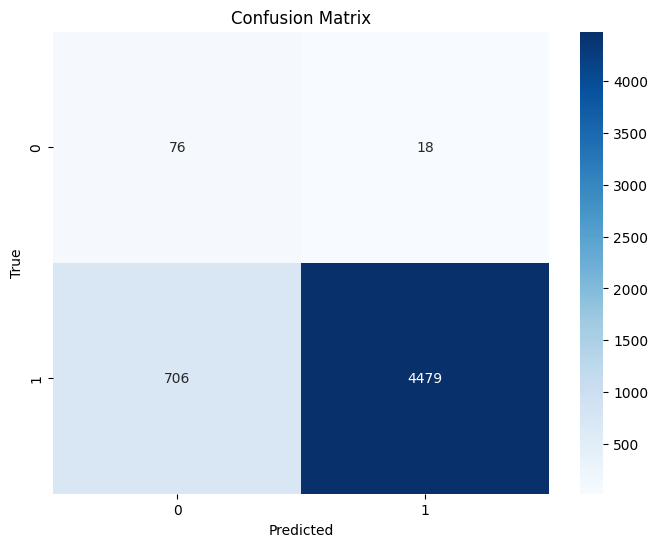

In [ ]:
# Plot confusion_matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_et, annot=True, fmt="d", cmap="Blues",
            xticklabels=np.unique(y_test),
            yticklabels=np.unique(y_test))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
y_score_et = pipeline_et.predict_proba(test_set)[:, 1]  # Probabilities for the positive class

In [ ]:
roc_auc_score(y, pipeline_et.predict_proba(X)[:, 1])

np.float64(1.0)

In [ ]:
# Compute ROC curve
fpr_et, tpr_et, thresholds_et = roc_curve(y_test, y_score_et)
# Compute AUC (Area Under the Curve)
roc_auc_et = auc(fpr_et, tpr_et)

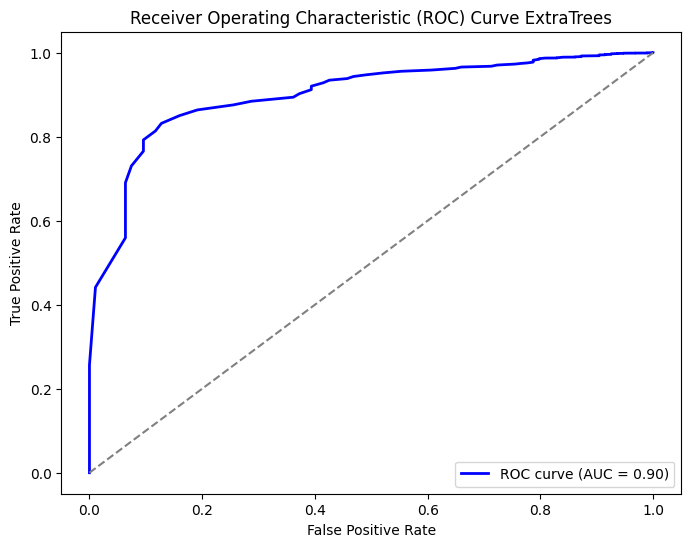

In [ ]:
# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr_et, tpr_et, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc_et:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Random classifier line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve ExtraTrees')
plt.legend(loc='lower right')
plt.show()

## TESTING CNN

In [ ]:
# Valuto il modello sul dataset di test
test_loss, test_acc = model.evaluate(test_set, y_test, verbose=2)
print('Test accuracy:', test_acc, '\n Test loss:', test_loss)

165/165 - 1s - 5ms/step - accuracy: 0.9831 - loss: 0.1413
Test accuracy: 0.983140766620636 
 Test loss: 0.14131462574005127


#### Plot learning curves CNN-1D

In [ ]:
def plot_training_curves(history):
    df = pd.DataFrame(history.history, index=history.epoch)    # create a pandas dataframe
    plt.figure(figsize=(8, 6))
    df.plot(ylim=(0, max(1, df.values.max())))                 #  plot all the metrics

    loss = history.history['loss'][-1]
    acc = history.history['accuracy'][-1]
    plt.title('Loss: %.3f, Accuracy: %.3f' % (loss, acc))

<Figure size 800x600 with 0 Axes>

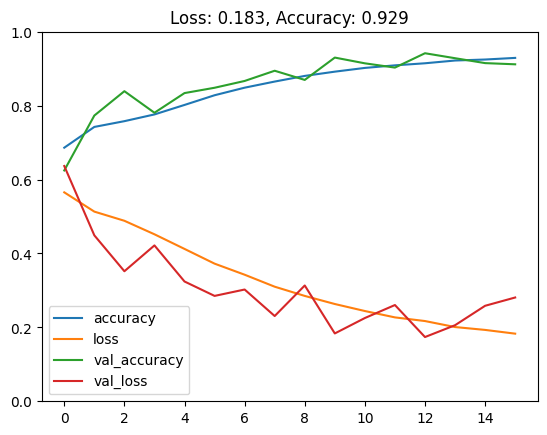

In [ ]:
plot_training_curves(hst)

In [ ]:
# Salva i valori su file .log
# Trova la migliore epoca
best_epoch = max(range(len(hst.history['val_accuracy'])), key=lambda i: hst.history['val_accuracy'][i])
best_val_acc = hst.history['val_accuracy'][best_epoch]
best_val_loss = hst.history['val_loss'][best_epoch]
best_acc = hst.history['accuracy'][best_epoch]
best_loss = hst.history['loss'][best_epoch]

# Recupera l'ultima epoca
last_epoch = len(hst.history['loss']) - 1
last_loss = hst.history['loss'][last_epoch]
last_acc = hst.history['accuracy'][last_epoch]
last_val_loss = hst.history['val_loss'][last_epoch]
last_val_acc = hst.history['val_accuracy'][last_epoch]

with open('/content/cnn_results.log', 'w') as log_file:
    log_file.write("Best Result:\n")
    log_file.write(f"Epoch {best_epoch + 1},  Train Accuracy: {best_acc:.4f}, Train Loss: {best_loss:.4f}\n")
    log_file.write(f"Val Accuracy: {best_val_acc:.4f}, Val Loss: {best_val_loss:.4f}\n")

    log_file.write("\nLast Result:\n")
    log_file.write(f"Epoch {last_epoch + 1}, Train Accuracy: {last_acc:.4f}, Train Loss: {last_loss:.4f}\n")
    log_file.write(f"Validation Accuracy: {last_val_acc:.4f}, Validation Loss: {last_val_loss:.4f}")